In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import os 
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from vs2_1_plssvd_eval_utils import validation_run_name
from vs2_1_plssvd_figures import (load_evaluation, plot_first_iteration, plot_correlation_matrix,
    plot_evaluation_summary, plot_prepared_permutations, load_comparison,
    plot_prepared_diagnostics, plot_prepared_pca)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


# PLSSVD evalutation
- 100 independently shuffled five-fold iterations. 
- Choose N_COMPONENTS below without fitting again.

- Prior:
```bash
submit_to_cluster -n 2 -q long.q "python plssvd_eval.py --meg-kind paired_coverage --max-components 100 --n-splits 5 --n-iterations 50 --perm both --perm-type time_block" --project MINDLAB2021_MEG-TempSeqAges
```

--perm ieeg|meg|both \
--perm-type time_cirular_shift|time_block|time_point|space|phase \

```bash
submit_to_cluster -n 2 -q short.q "python -u plssvd_postprocess.py --runs-dir out/plssvd_eval_equal_var/paired_coverage --components 10 --perm meg --perm-type time_block" --project MINDLAB2021_MEG-TempSeqAges

```

- `--all-runs` instead of `--perm`/`--perm-type` to process every runs

In [3]:
MEG_KIND = 'paired_coverage'
PERM = 'none'  # 'none', 'ieeg', 'meg', 'both'
PERM_TYPE = 'none'  # 'none', 'time_cirular_shift', 'time_block', 'time_point', 'phase'
N_COMPONENTS = 10

RUNS_DIR = ROOT / 'out' / 'plssvd_eval_equal_var' / MEG_KIND
OUTPUT_DIR = RUNS_DIR / validation_run_name(PERM, PERM_TYPE)

PCA_ABSOLUTE = True # abs of person

evaluation = load_evaluation(OUTPUT_DIR, N_COMPONENTS)
display(pd.Series(evaluation['metadata']['options'], name='Saved fit settings'))

first_iteration = evaluation['metadata']['iterations'][0]

Prepared evaluation: 50/50 iterations; 10/100 fitted components. No fitting or evaluation is run.


repeats                                       5
n_components                                100
n_iterations                                 50
perm                                       None
perm_type                                  None
block_seconds                              0.36
seed                                       2026
split_unit                                trial
block_scaling                    equal_variance
ridge                                     0.001
max_gram_gib                                2.0
schema_version                                6
meg_kind                        paired_coverage
condition_mode                          average
iteration_layout    iteration_000/model_000.npz
Name: Saved fit settings, dtype: object

## Goodness on held-out data: signal fit and shared covariance

**1. Own-modality reconstruction.** For each modality, project the test signals onto the training-learned PLS weight space and reconstruct them using the same weights:
Any training whole-modality scale is undone for reconstruction. `ieeg_reconstruction_fraction` and `meg_reconstruction_fraction` report how much of each test signal the learned space retains.

**2. Cross-modal prediction.** Training ridge regressions map MEG scores to iEEG features and iEEG scores to MEG features. `predict_ieeg_q2` and `predict_meg_q2` are `1 − test squared error / training-mean-baseline squared error`. Positive Q² improves on that baseline; negative Q² is worse.

**3. Held-out cross-covariance.** Let C be the full test-feature cross-covariance after partition centering and the training-learned scaling, and let Wx/Wy be the training PLS weights. The test score covariance matrix is `Wx.T @ C @ Wy`. `crosscov_energy_fraction` is its squared Frobenius norm divided by `||C||F²`.This is the fraction of observed test cross-covariance energy retained by the trained spaces.

Also report `mean_paired_covariance` (signed diagonal mean in native score units), per-component train/test covariance, `paired_crosscov_energy_fraction` (diagonal energy only), and signed paired score Pearson r. A covariance fraction can be high even when the absolute shared signal is weak, so inspect these measures together. Covariance retention relative to training is in the prepared metric tables and can exceed one or become negative.

All prepared metrics use the selected leading k components. The cross-modal ridge predictor is recalibrated using saved training statistics and the k-specific ridge penalty. The full feature-space cross-covariance denominator stays fixed. Exploring k on test performance is descriptive, not an unbiased model-selection procedure.


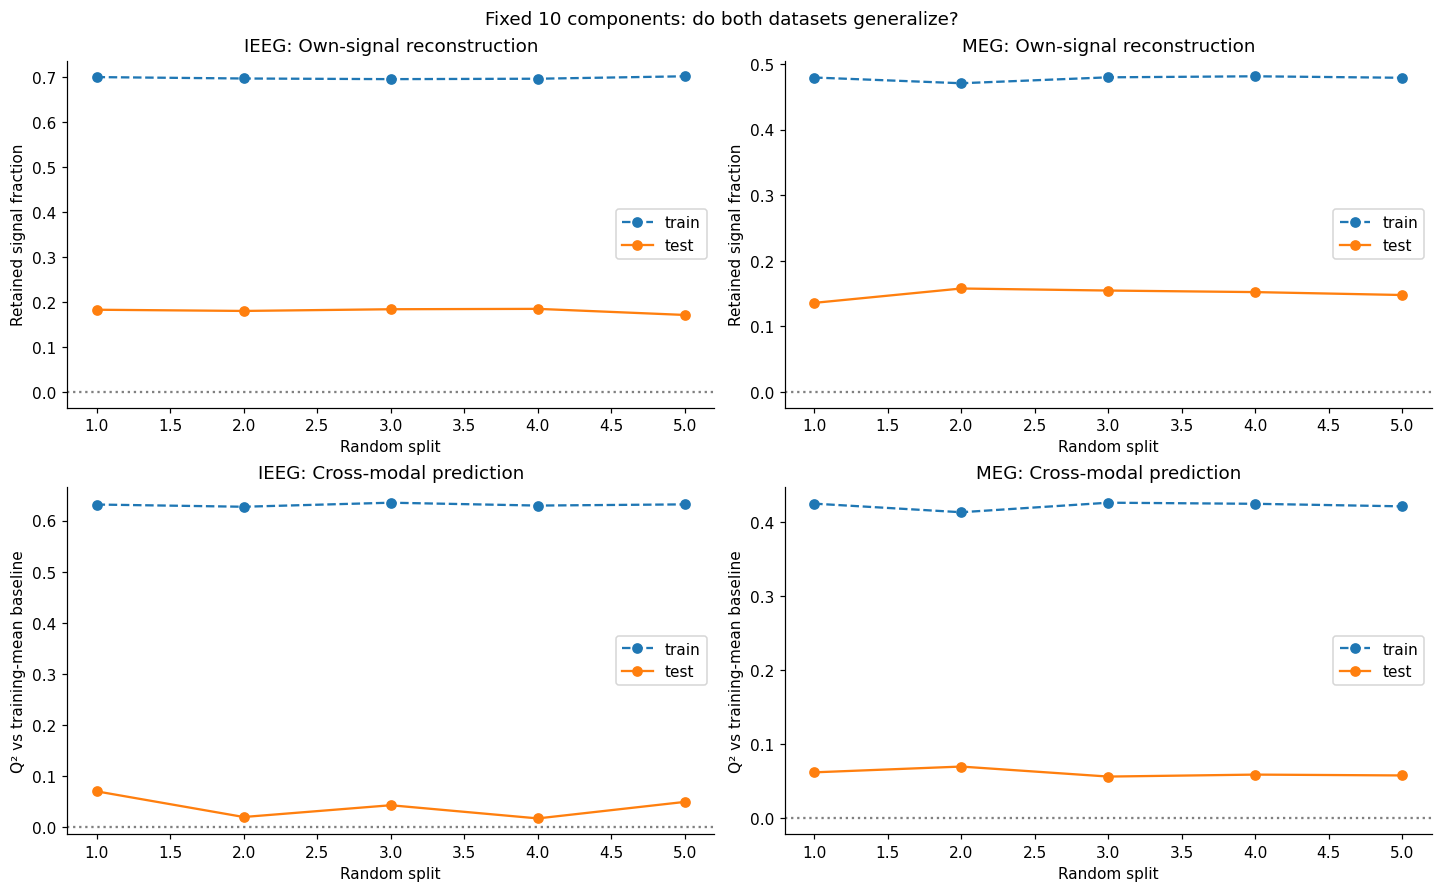

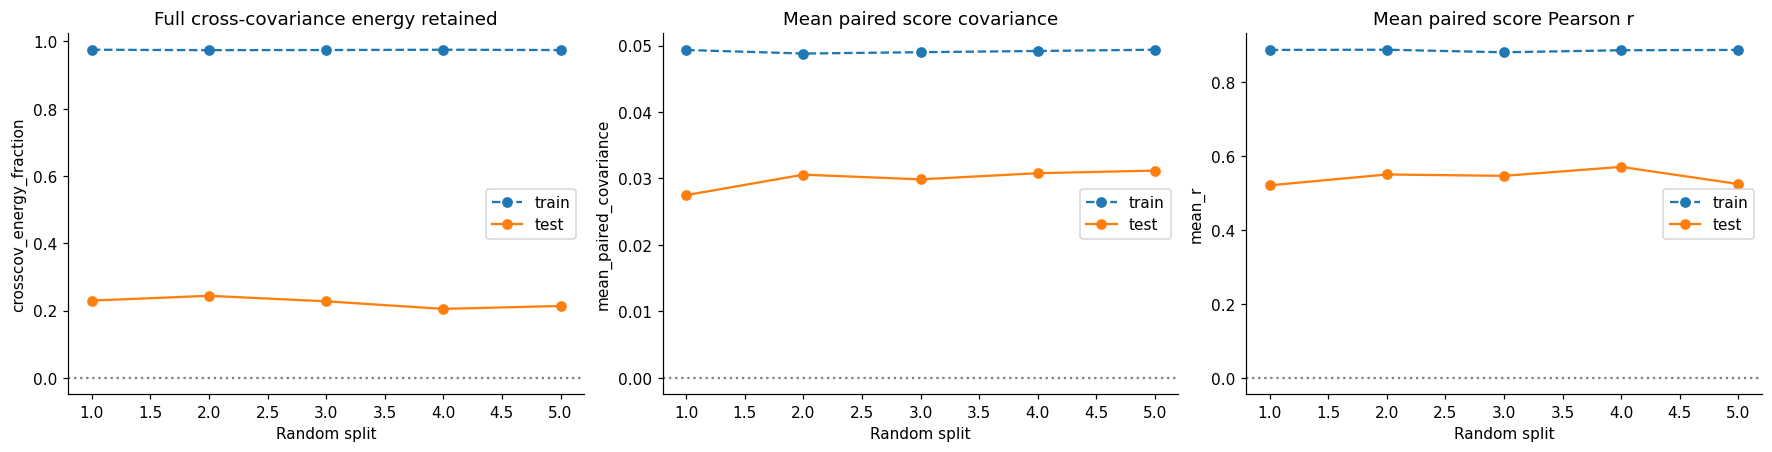

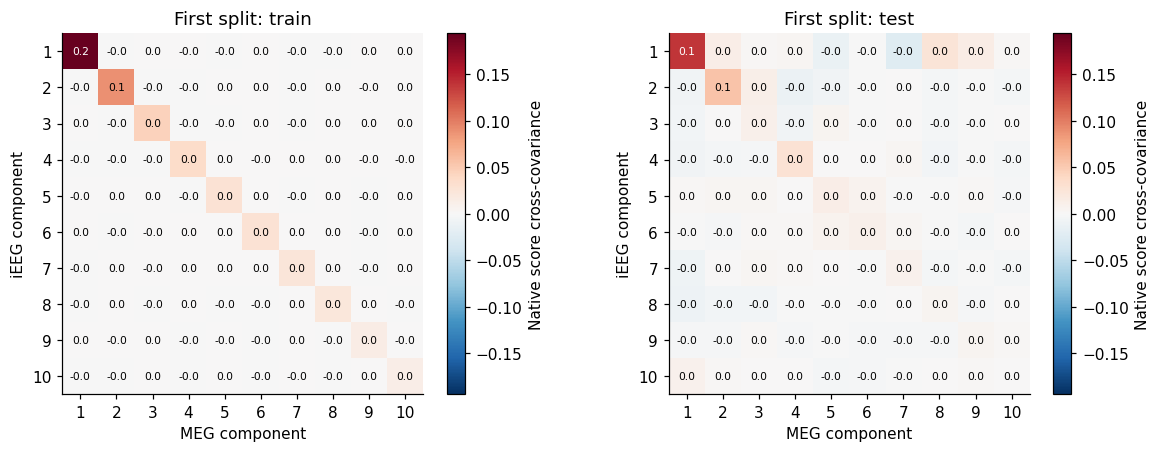

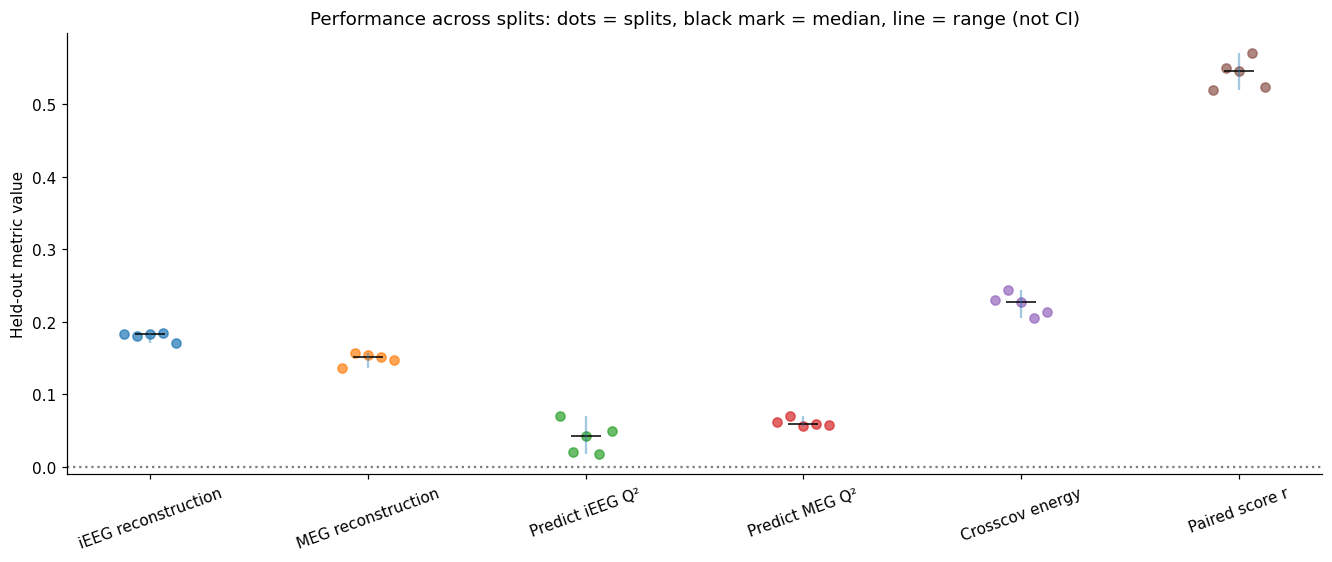

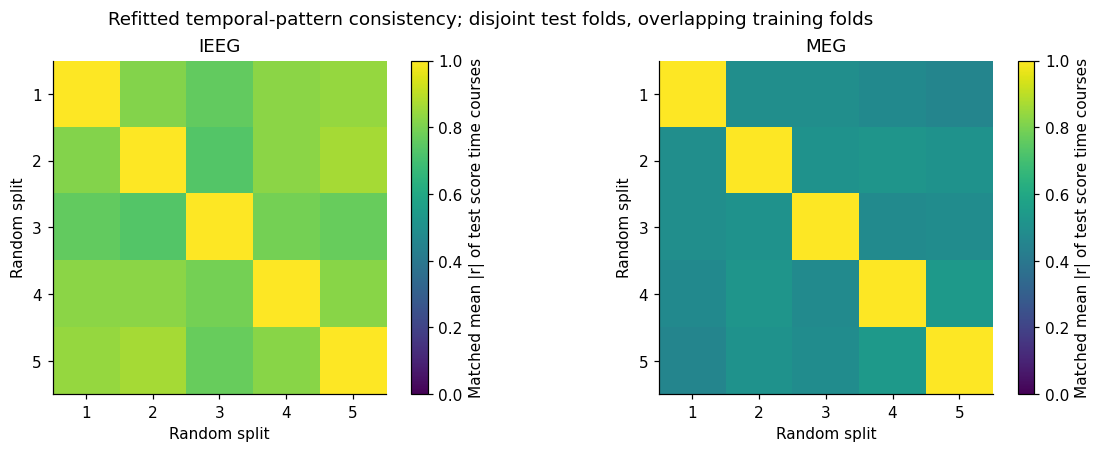

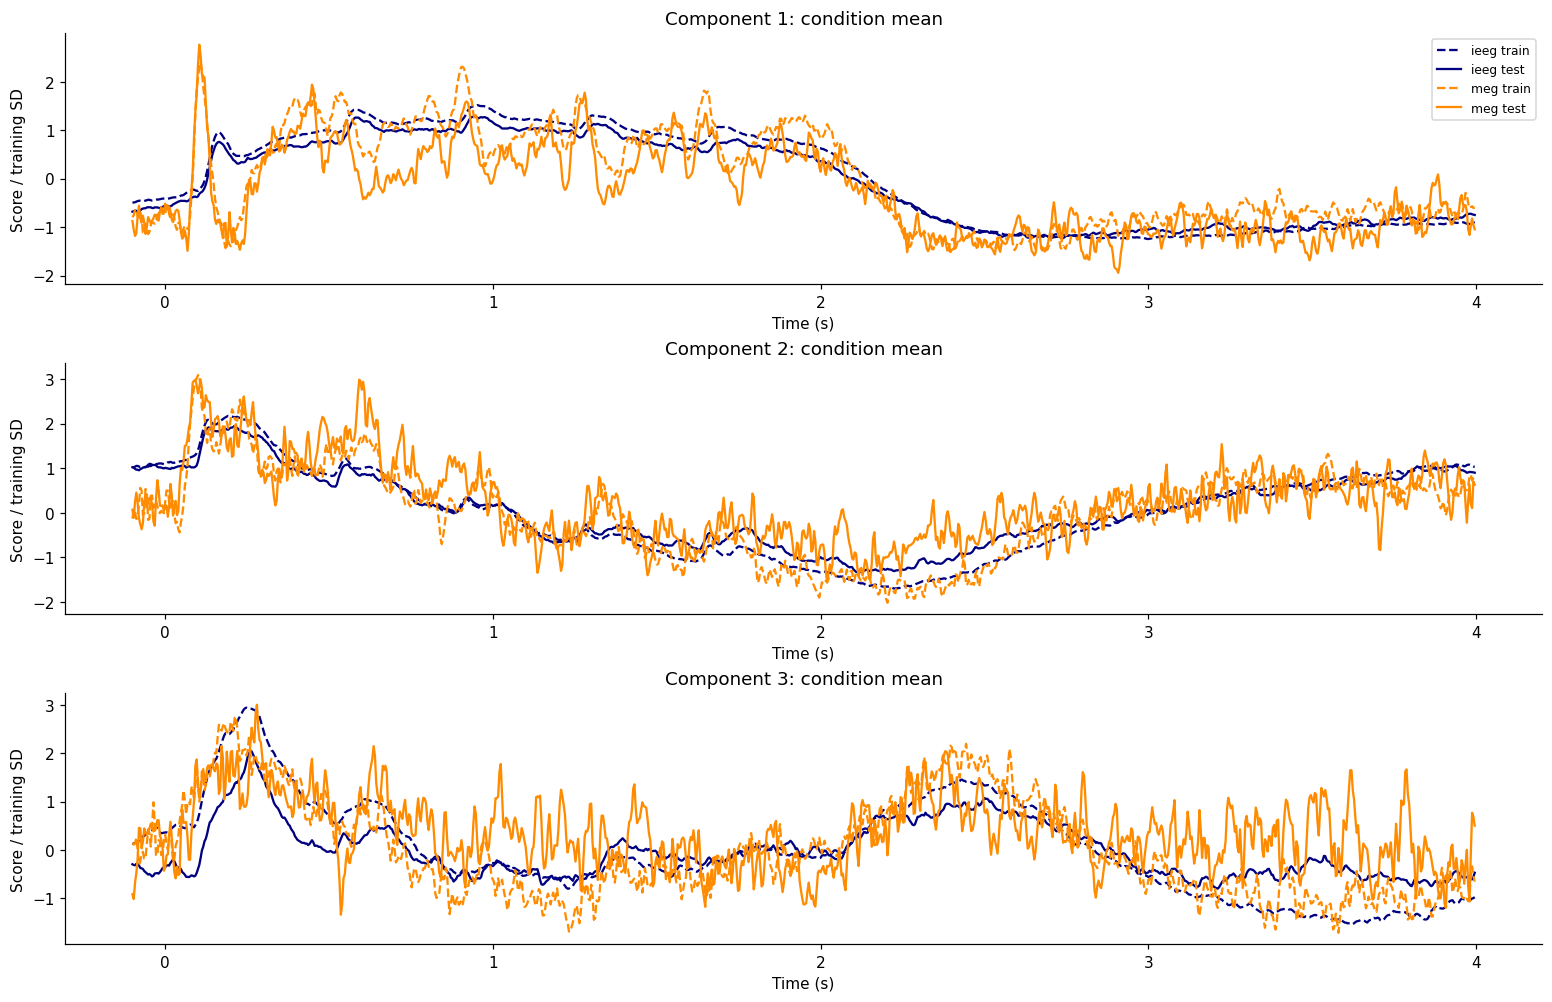

In [5]:
plot_first_iteration(evaluation)


## First-iteration cross-modal test correlations
Mean absolute held-out Pearson correlation across the five folds, in native component order. Uses the selected leading components.


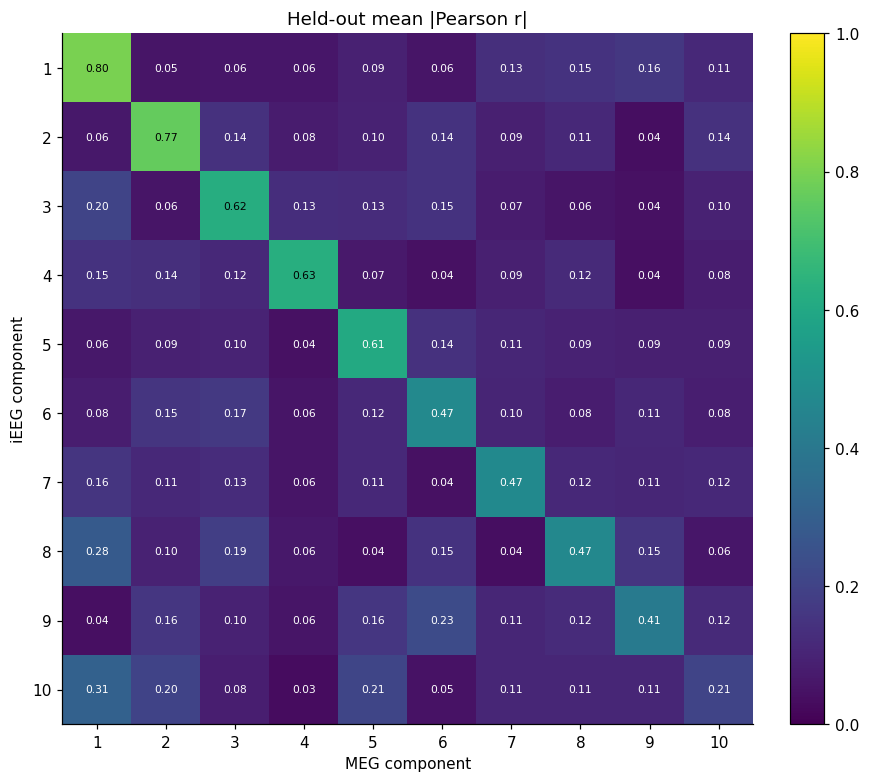

In [7]:
fig = plot_correlation_matrix(evaluation['first_test_correlation'])
display(fig)
plt.close(fig)


## Evaluation over available iterations
Time-course pairs are oriented using the largest absolute **training iEEG** score entry; both modalities share this sign.\
Components remain in native singular-value order. \

`iteration_stability` also reports matched temporal-pattern correlations against iteration 1 (fold 1), separately by modality and train/test. Matching is descriptive only and does not alter any performance metrics.


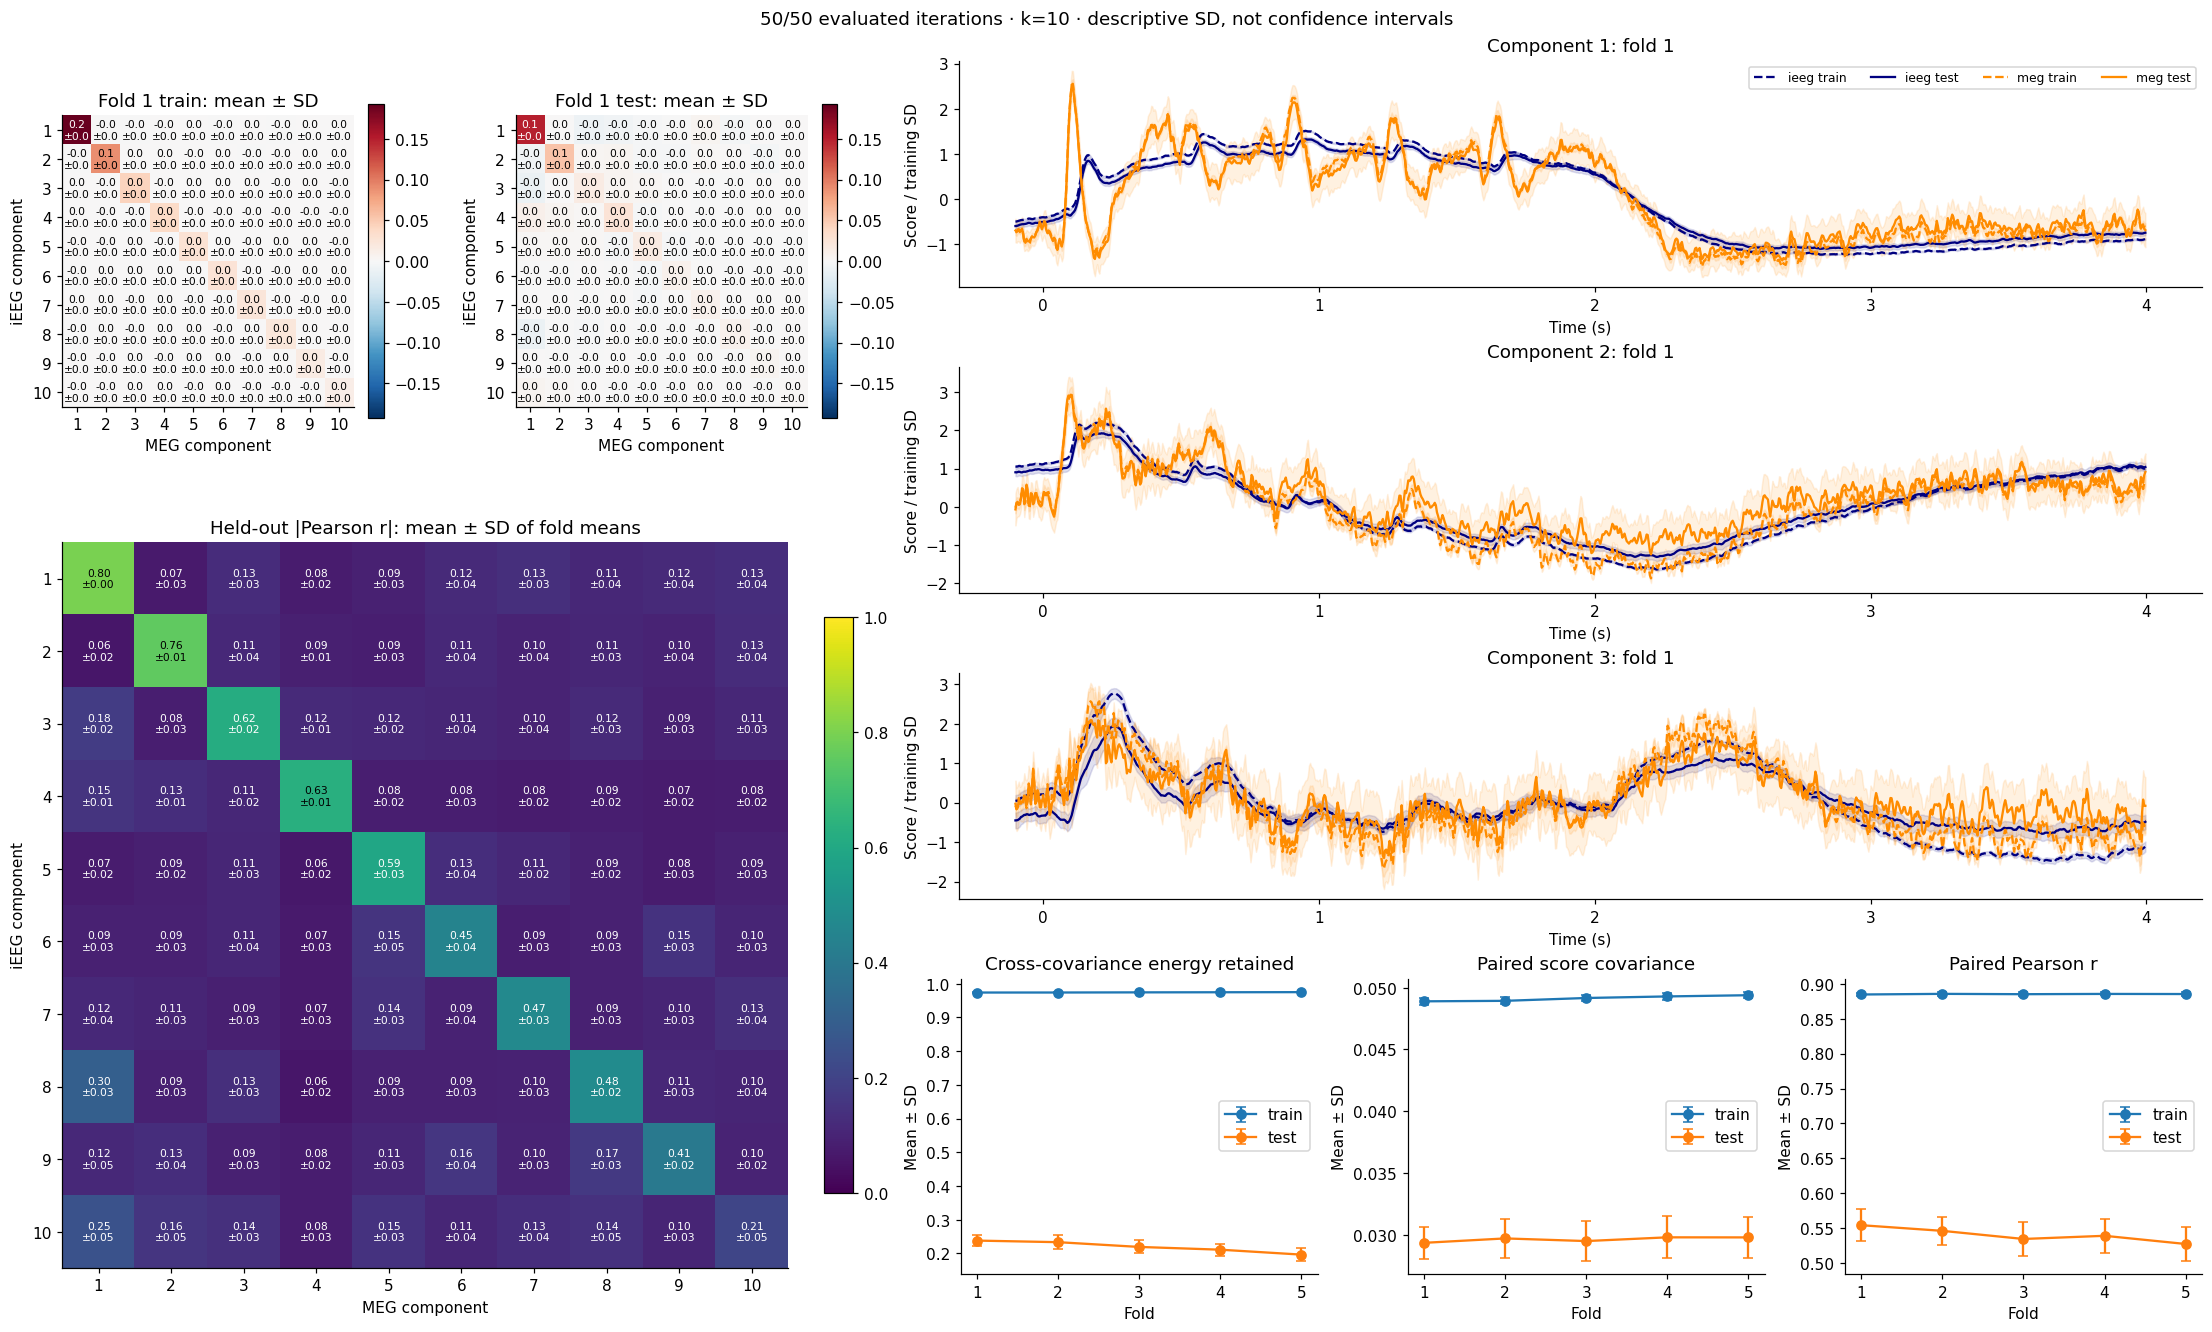

In [8]:
#display(evaluation['metric_summary'].round(3))
#display(evaluation['iteration_stability'].round(3))
fig = plot_evaluation_summary(evaluation)
display(fig)
plt.close(fig)


In [1]:
fig,ax = plt.subplots(1, 2)
ax[0].plot(evaluation['arrays']['test_covariance_mean'].diagonal()[:10])
ax[0].set_title('Test Covariance Mean')

ax[0].plot(evaluation['arrays']['test_correlation_absolute_mean'].diagonal()[:10])
ax[0].set_title('Test Correlation Mean')

for a in ax :
    a.grid()
    

NameError: name 'plt' is not defined

## Permutation effects across iterations

Permutations operate on each participant's condition trial means **before fitting**. \
Time permutations are independent per channel and shared across conditions, train/test and folds within an iteration. \
Blocks default to **0.36 seconds**, rounded to samples; the final short block is retained. \
Space independently shuffles channels at each time point, sharing that transform across conditions and partitions. \ 

(`plssvd_postprocess.py`)


Prepared matched comparison: 50 shared iterations.
Prepared matched comparison: 50 shared iterations.
Prepared matched comparison: 50 shared iterations.


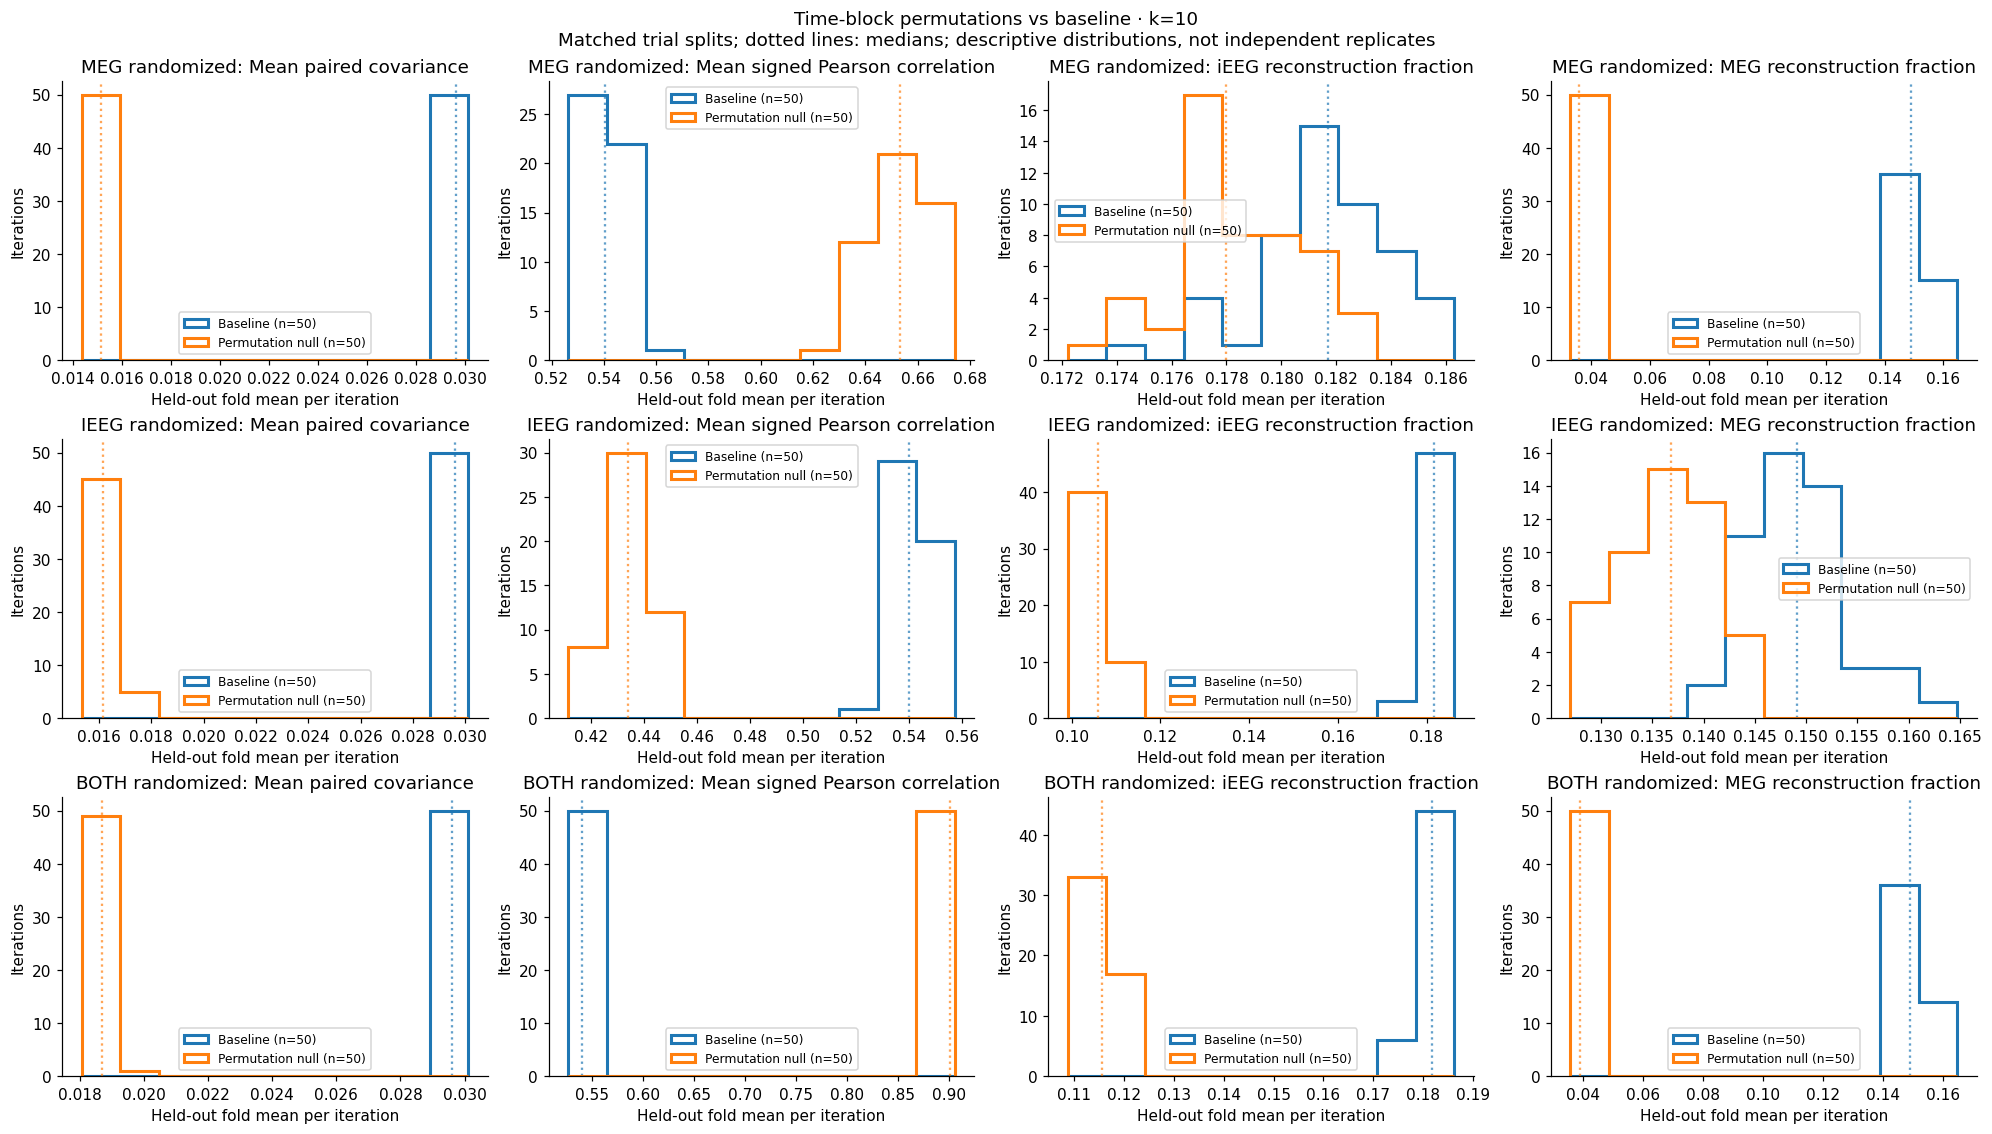

In [13]:
from plssvd_figures import plot_null_comparison
PERMUTATION_TYPE = 'time_block' # time_circular_shift, time_block, time_point, space, or phase.
N_COMPONENTS =10
fig = plot_null_comparison(RUNS_DIR, N_COMPONENTS, perm_type=PERMUTATION_TYPE)
display(fig)
plt.close(fig)


## Component selection: stable excess covariance against a selected null
```bash
submit_to_cluster -n 2 -q short.q "python -u plssvd_select_components.py --components 10 --perm meg --perm-type time_point" --project MINDLAB2021_MEG-TempSeqAges
```

For each rank, use the 95th percentile of the selected null's iteration fold-mean signed covariance, floored at zero. Retain the contiguous leading ranks whose baseline covariance strictly exceeds this threshold in at least 90% of matched iterations. Thresholds are configurable in the script. Correlation and reconstruction are supporting diagnostics only; reconstruction is shown at the evaluated component count, not necessarily the selected count.

Null : 

`--perm`:  ieeg, meg, both` \
SELECTION_PERM 

`--perm-type` time_cirular_shift|time_block|time_point|space|phase \
SELECTION_NULL_TYPE

Prepared matched comparison: 50 shared iterations.
Selected components: 10


,component,null_threshold,effective_threshold,support,passes,retained,observed_median,observed_low,observed_high
0,1,0.001422,0.001422,1.00,True,True,0.151588,0.148692,0.153211
1,2,0.001356,0.001356,1.00,True,True,0.055281,0.052662,0.057513
2,3,0.001315,0.001315,1.00,True,True,0.016477,0.015551,0.017339
3,4,0.001269,0.001269,1.00,True,True,0.025829,0.025241,0.026407
4,5,0.001182,0.001182,1.00,True,True,0.015969,0.013531,0.017014
5,6,0.001125,0.001125,1.00,True,True,0.008147,0.006941,0.010302
6,7,0.001110,0.001110,1.00,True,True,0.008339,0.007327,0.009242
7,8,0.001075,0.001075,1.00,True,True,0.007763,0.006977,0.008506
8,9,0.001090,0.001090,1.00,True,True,0.005179,0.004726,0.005651
9,10,0.001089,0.001089,0.96,True,True,0.002169,0.001211,0.002890


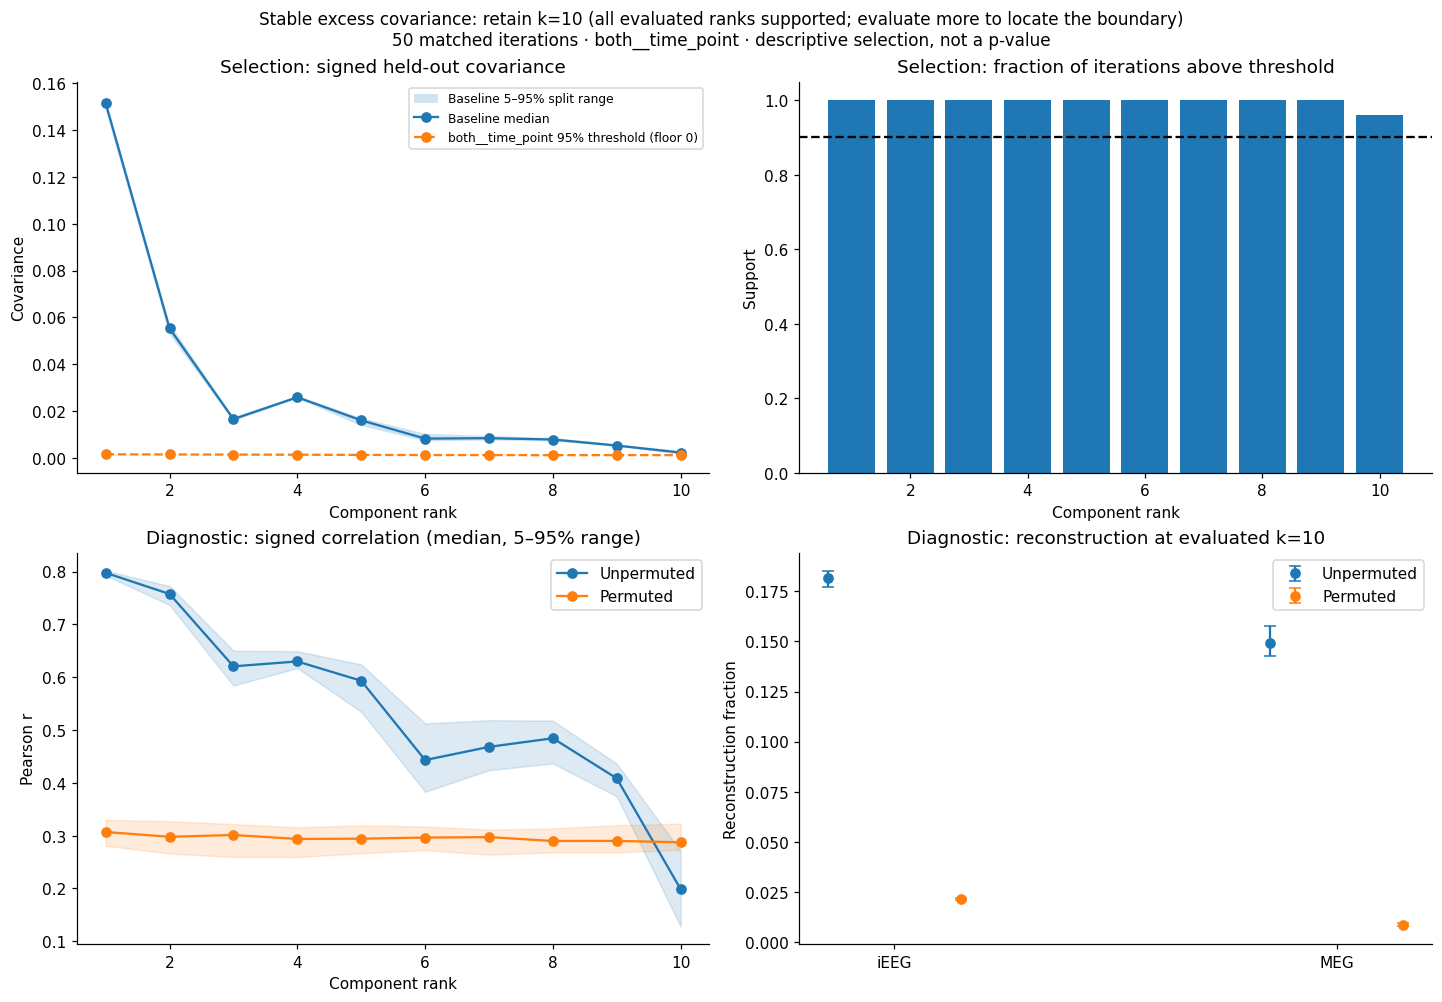

In [16]:
from vs2_1_plssvd_select_components import load_selection, plot_selection

SELECTION_COMPONENTS = 10
SELECTION_PERM = 'both'  # 'ieeg', 'meg', or 'both'
SELECTION_NULL_TYPE = 'time_point'  # time_cirular_shift, time_block, time_point, space, phase
selection_result = load_selection(RUNS_DIR, n_components=SELECTION_COMPONENTS, perm=SELECTION_PERM, perm_type=SELECTION_NULL_TYPE)
print(f"Selected components: {selection_result['summary']['selected_k']}")
display(selection_result['selection'])
selection_fig = plot_selection(selection_result)
display(selection_fig)
plt.close(selection_fig)


## PCA matching 

```bash
submit_to_cluster -n 2 -q short.q "python -u plssvd_select_components.py --components 10 --perm meg --perm-type time_point" --project MINDLAB2021_MEG-TempSeqAges
```

plot the figure here 